# CMIIC : seuil historique contre seuil analytique

Même grille, mêmes graphes et mêmes jeux de données que le scaling de juillet 2026 (seed 42, 30 graphes).
`CPC` et `CMIIC` sont le run de juillet (CMIIC en mode Naive, pénalité α = 0.05). `nouveau CMIIC` est le run du 29 octobre 2026 (mode Analytic, split, seuil μ_n + z σ_tot, α = 0.05).

Mêmes figures que la section scaling du rapport, une par cellule : temps d'exécution, puis SHD, F1 et TPR sur les CPDAG, puis sur les squelettes. Moyenne plus ou moins erreur standard sur les 30 graphes.

**Attention.** Ce run change deux choses à la fois par rapport à CMIIC : le seuil analytique sur les tests à deux points, et la pénalité à trois points mise à 0 au lieu de −α, ce qui oriente presque toutes les arêtes. Le gain sur les CPDAG vient en grande partie du second changement. Voir positionnement_et_priorites.md, section 6, dans cmiic_wip.

In [42]:
import sys; sys.path.insert(0, "../../..")
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from experiments.scaling.io import load_results

# Police façon LaTeX, comme les figures du rapport cbnsl_benchmark_report
matplotlib.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman", "CMU Serif", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "axes.unicode_minus": False,
    "font.size": 12,
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
})

JULY = {
    "sem_gaussian": "2026-07-30_14h34_sem_gaussian",
    "sem_laplace": "2026-07-30_23h47_sem_laplace",
    "cbn_unif_gauss": "2026-07-31_02h24_cbn_unif_gauss",
    "cbn_exp_clayton": "2026-07-31_06h33_cbn_exp_clayton",
    "cbn_unif_mixture": "2026-07-31_10h35_cbn_unif_mixture"
}
NEW = {
    "sem_gaussian": "2026-10-29_18h55_sem_gaussian_3pt_sans_penalite",
    "sem_laplace": "2026-10-29_20h19_sem_laplace_3pt_sans_penalite",
    "cbn_unif_gauss": "2026-10-29_21h38_cbn_unif_gauss_3pt_sans_penalite",
    "cbn_exp_clayton": "2026-10-30_00h46_cbn_exp_clayton_3pt_sans_penalite",
    "cbn_unif_mixture": "2026-10-30_03h53_cbn_unif_mixture_3pt_sans_penalite"
}

# Mêmes couleurs que la légende du rapport pour CPC et CMIIC, couleur libre pour le nouveau
LABELS = {"CPC": "CPC", "CMIIC": "CMIIC", "CMIIC_analytic": "nouveau CMIIC"}
ALGOS = ["CPC", "CMIIC", "nouveau CMIIC"]
PALETTE = {"CPC": "tab:blue", "CMIIC": "tab:orange", "nouveau CMIIC": "tab:cyan"}

def load_pair(gen):
    """Lignes CPC et CMIIC du run de juillet et run du seuil analytique, pour un générateur."""
    old = load_results(f"{JULY[gen]}/results.csv")
    old = old[old.algo.isin(["CPC", "CMIIC"])]
    new = load_results(f"{NEW[gen]}/results.csv")
    df = pd.concat([old, new], ignore_index=True)
    df["algo"] = df.algo.map(LABELS)
    return df

def plot(df, n_vars, y, ylabel):
    """Une figure, moyenne +/- erreur standard sur les graphes, une courbe par algorithme."""
    data = df[df.n_vars == n_vars]
    fig, ax = plt.subplots(figsize=(6, 4))
    sns.lineplot(
        data=data, x="n_samples", y=y,
        hue="algo", hue_order=ALGOS, palette=PALETTE,
        errorbar="se", marker="o", ax=ax,
    )
    ax.set_xlabel("Number of samples")
    ax.set_ylabel(ylabel)
    ax.legend(title=None)
    fig.tight_layout()
    plt.show()

# SEM Gaussian

In [43]:
df = load_pair("sem_gaussian")

## 10 variables

### Temps d'exécution

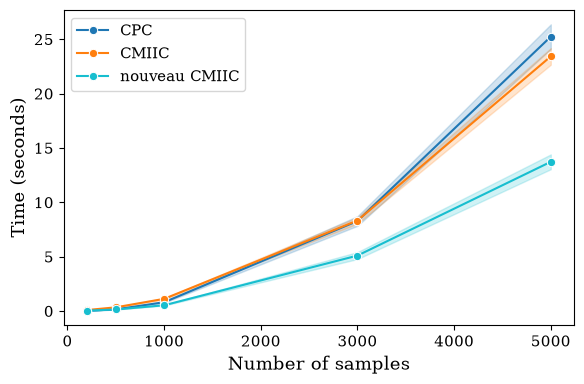

In [44]:
plot(df, 10, "time_s", "Time (seconds)")

### Sur les CPDAG

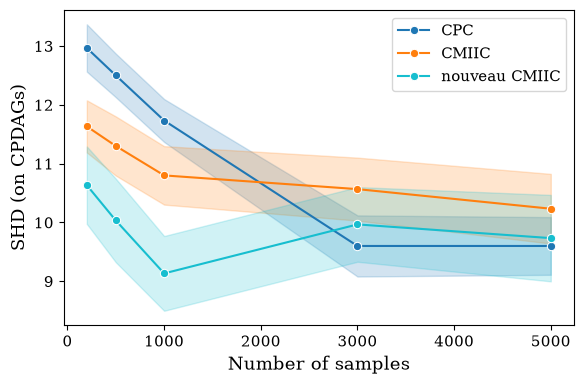

In [45]:
plot(df, 10, "SHD", "SHD (on CPDAGs)")

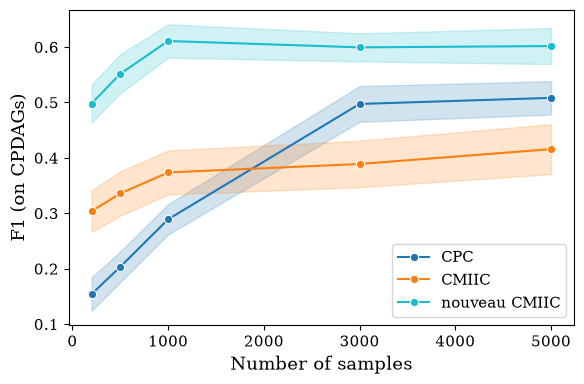

In [46]:
plot(df, 10, "F1-Score", "F1 (on CPDAGs)")

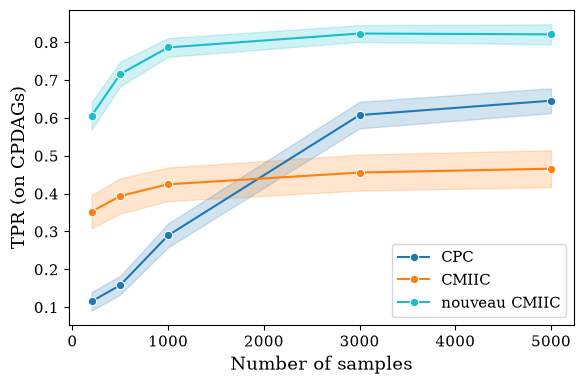

In [47]:
plot(df, 10, "TPR", "TPR (on CPDAGs)")

### Sur les squelettes

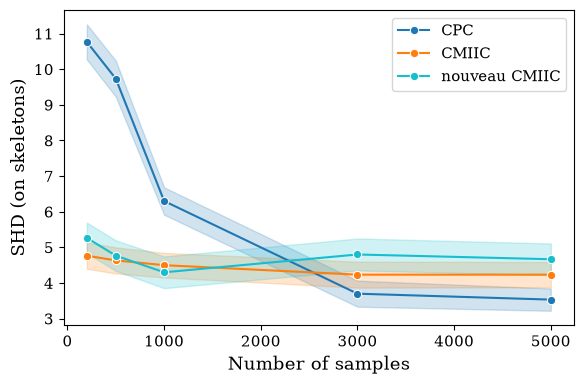

In [48]:
plot(df, 10, "SHD_skeleton", "SHD (on skeletons)")

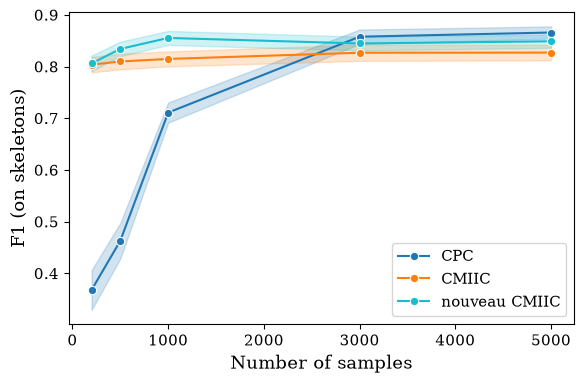

In [49]:
plot(df, 10, "F1-Score_skeleton", "F1 (on skeletons)")

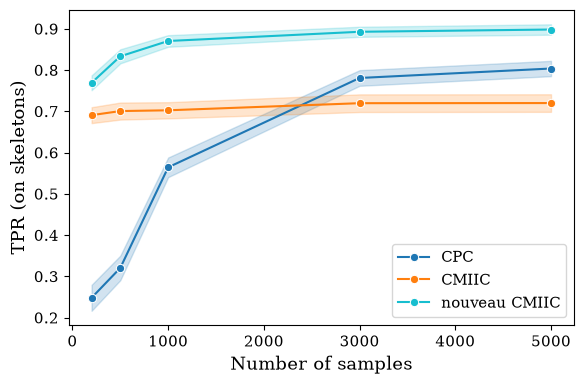

In [50]:
plot(df, 10, "TPR_skeleton", "TPR (on skeletons)")

## 20 variables

### Temps d'exécution

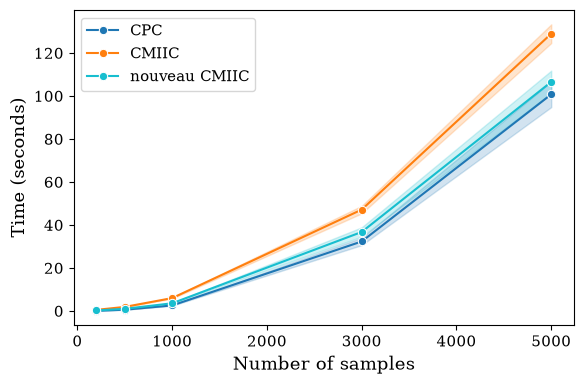

In [51]:
plot(df, 20, "time_s", "Time (seconds)")

### Sur les CPDAG

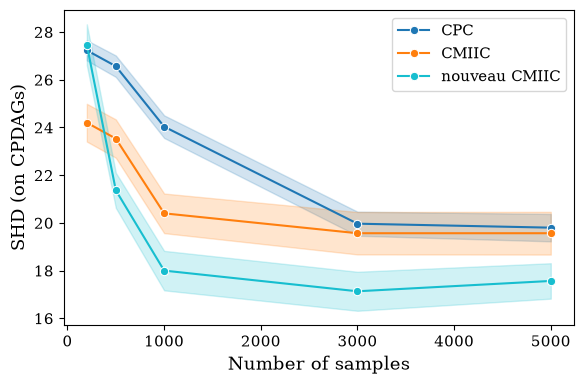

In [52]:
plot(df, 20, "SHD", "SHD (on CPDAGs)")

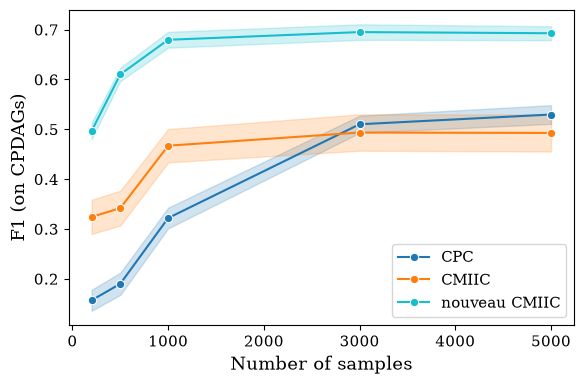

In [53]:
plot(df, 20, "F1-Score", "F1 (on CPDAGs)")

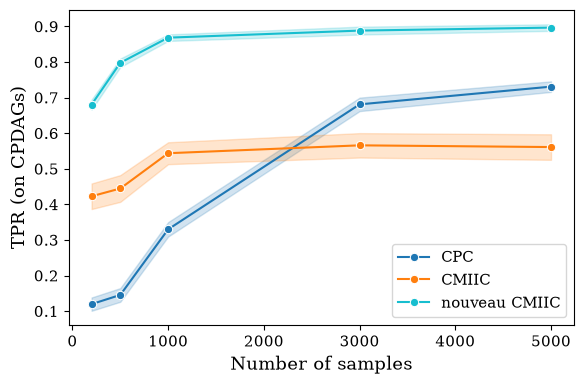

In [54]:
plot(df, 20, "TPR", "TPR (on CPDAGs)")

### Sur les squelettes

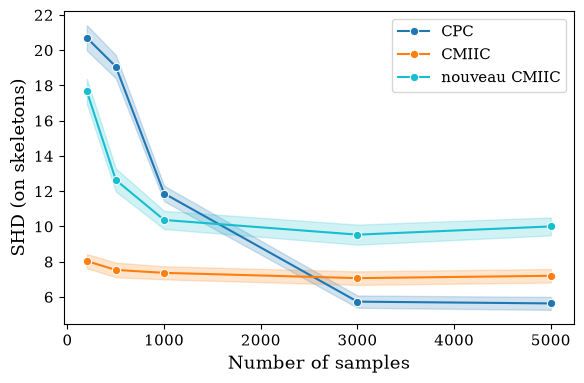

In [55]:
plot(df, 20, "SHD_skeleton", "SHD (on skeletons)")

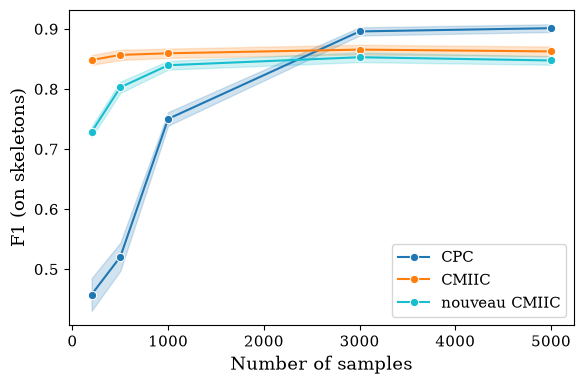

In [56]:
plot(df, 20, "F1-Score_skeleton", "F1 (on skeletons)")

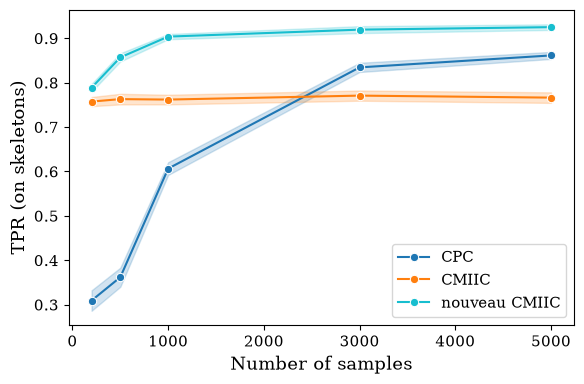

In [57]:
plot(df, 20, "TPR_skeleton", "TPR (on skeletons)")

# SEM Laplace

In [58]:
df = load_pair("sem_laplace")

## 10 variables

### Temps d'exécution

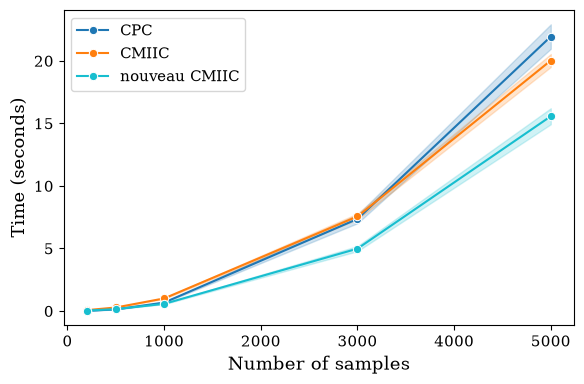

In [59]:
plot(df, 10, "time_s", "Time (seconds)")

### Sur les CPDAG

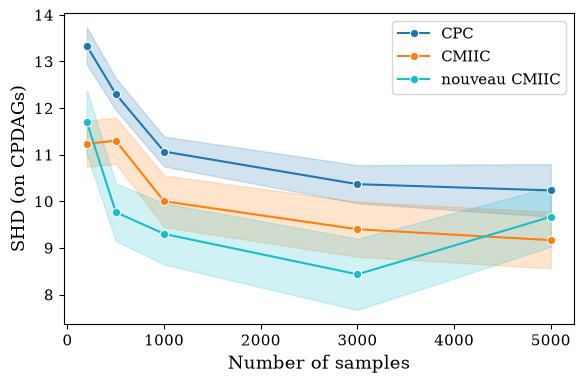

In [60]:
plot(df, 10, "SHD", "SHD (on CPDAGs)")

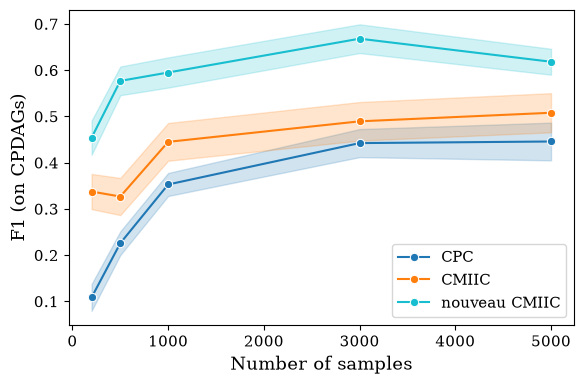

In [61]:
plot(df, 10, "F1-Score", "F1 (on CPDAGs)")

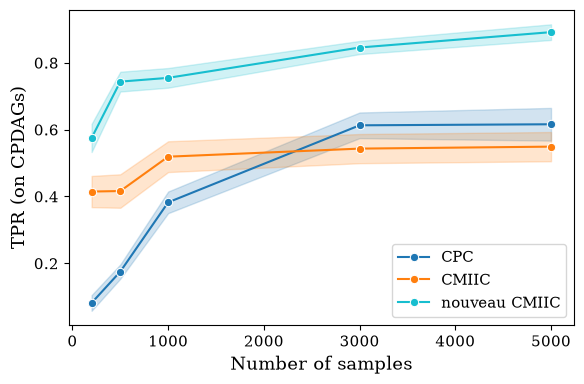

In [62]:
plot(df, 10, "TPR", "TPR (on CPDAGs)")

### Sur les squelettes

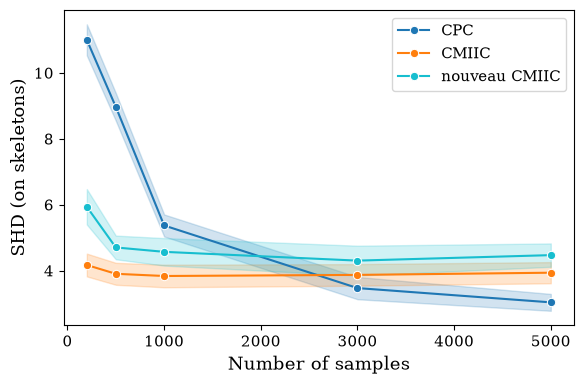

In [63]:
plot(df, 10, "SHD_skeleton", "SHD (on skeletons)")

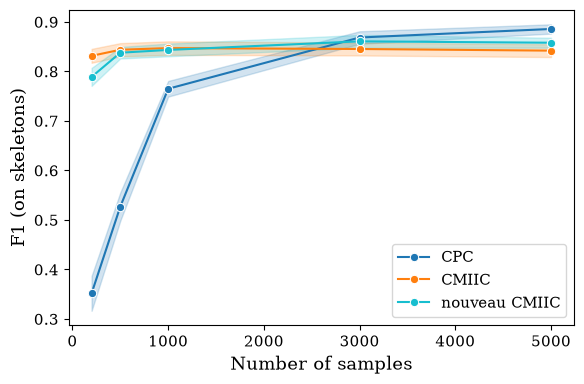

In [64]:
plot(df, 10, "F1-Score_skeleton", "F1 (on skeletons)")

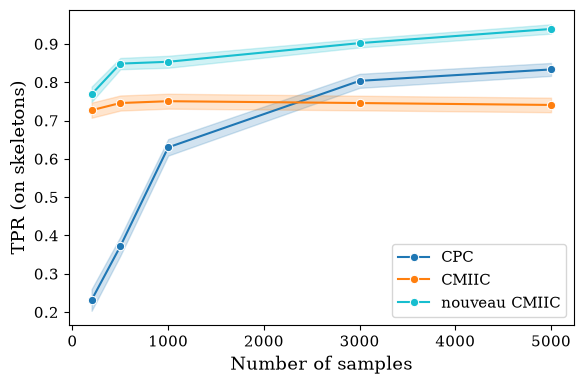

In [65]:
plot(df, 10, "TPR_skeleton", "TPR (on skeletons)")

## 20 variables

### Temps d'exécution

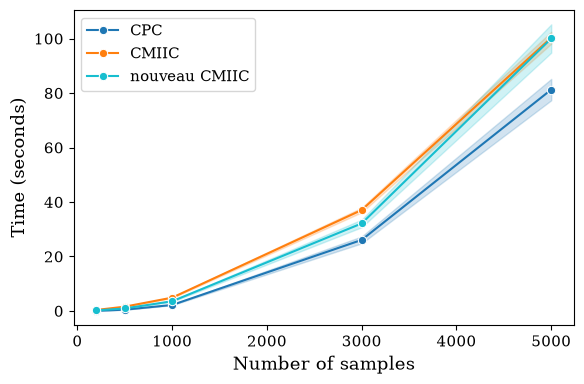

In [66]:
plot(df, 20, "time_s", "Time (seconds)")

### Sur les CPDAG

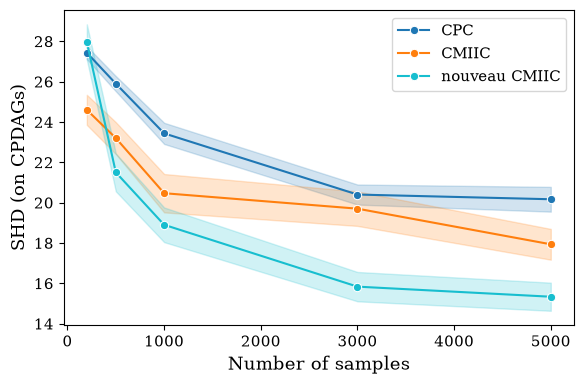

In [67]:
plot(df, 20, "SHD", "SHD (on CPDAGs)")

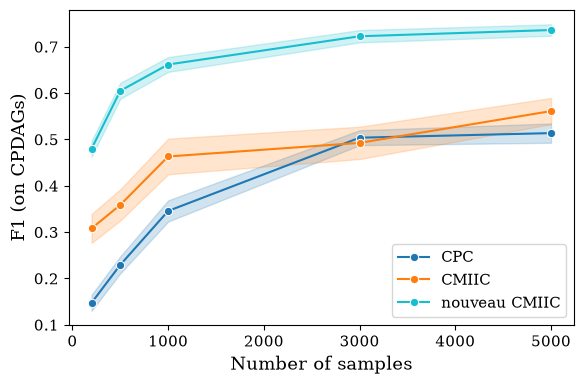

In [68]:
plot(df, 20, "F1-Score", "F1 (on CPDAGs)")

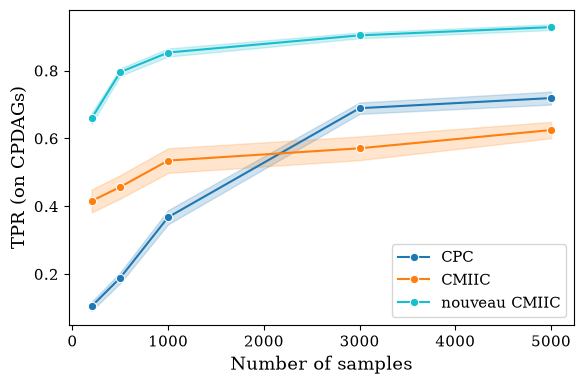

In [69]:
plot(df, 20, "TPR", "TPR (on CPDAGs)")

### Sur les squelettes

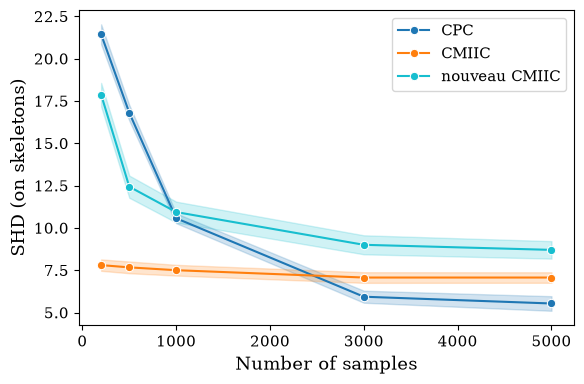

In [70]:
plot(df, 20, "SHD_skeleton", "SHD (on skeletons)")

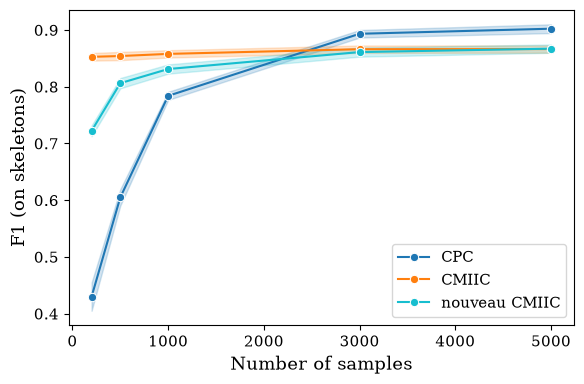

In [71]:
plot(df, 20, "F1-Score_skeleton", "F1 (on skeletons)")

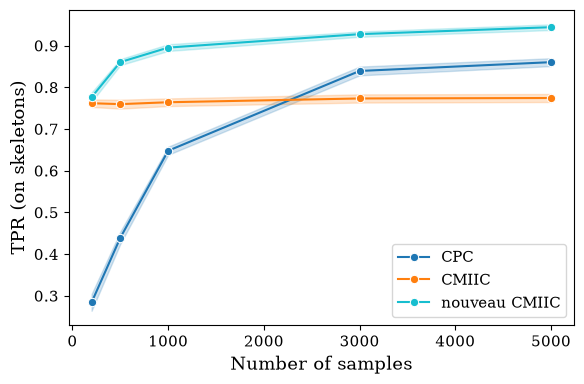

In [72]:
plot(df, 20, "TPR_skeleton", "TPR (on skeletons)")

# CBN Uniform/Gaussian

In [73]:
df = load_pair("cbn_unif_gauss")

## 10 variables

### Temps d'exécution

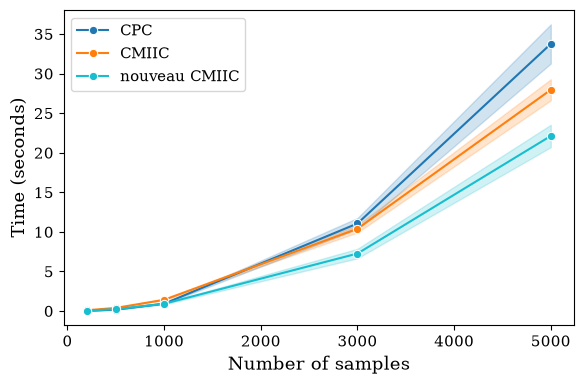

In [74]:
plot(df, 10, "time_s", "Time (seconds)")

### Sur les CPDAG

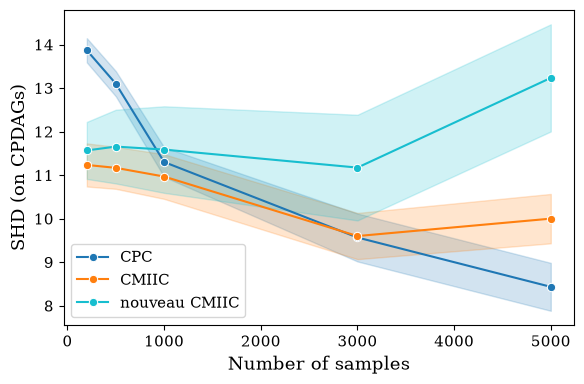

In [75]:
plot(df, 10, "SHD", "SHD (on CPDAGs)")

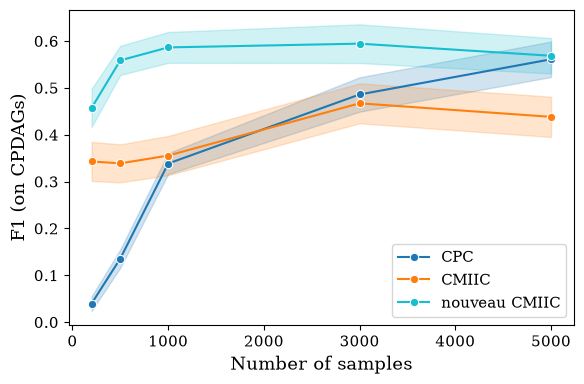

In [76]:
plot(df, 10, "F1-Score", "F1 (on CPDAGs)")

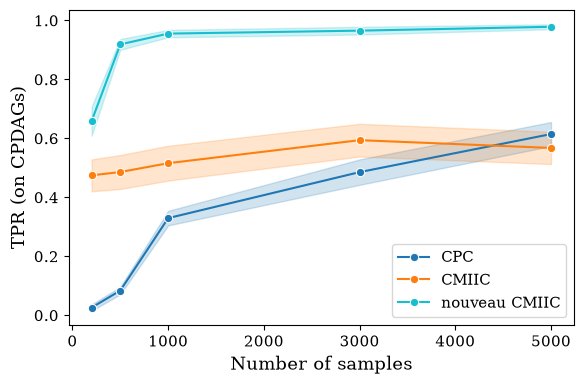

In [77]:
plot(df, 10, "TPR", "TPR (on CPDAGs)")

### Sur les squelettes

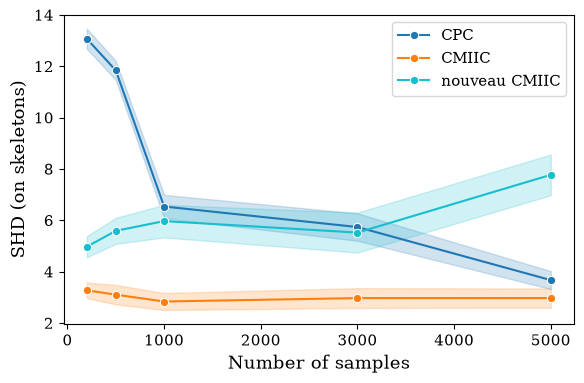

In [78]:
plot(df, 10, "SHD_skeleton", "SHD (on skeletons)")

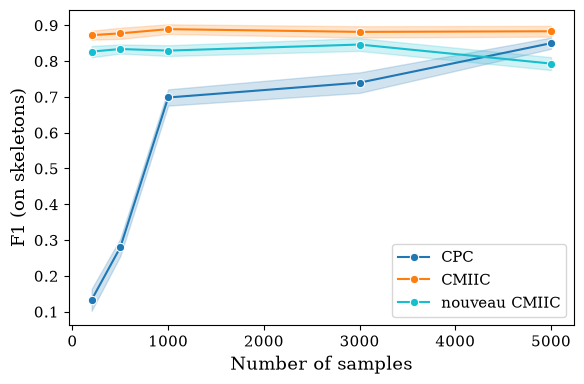

In [79]:
plot(df, 10, "F1-Score_skeleton", "F1 (on skeletons)")

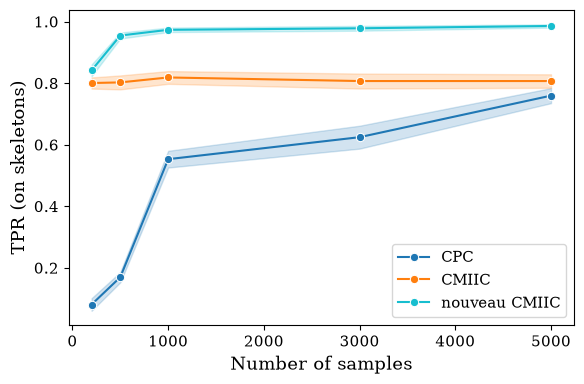

In [80]:
plot(df, 10, "TPR_skeleton", "TPR (on skeletons)")

## 20 variables

### Temps d'exécution

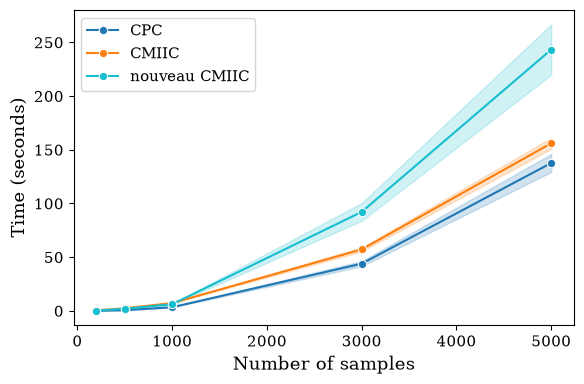

In [81]:
plot(df, 20, "time_s", "Time (seconds)")

### Sur les CPDAG

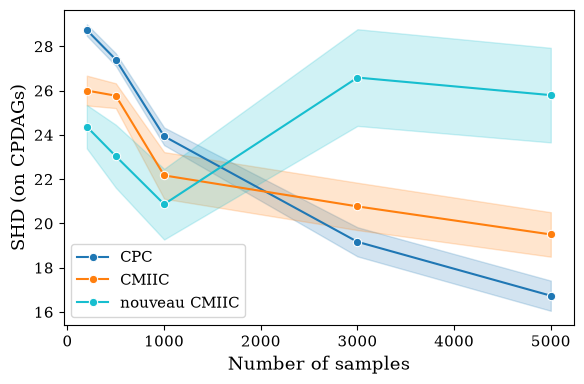

In [82]:
plot(df, 20, "SHD", "SHD (on CPDAGs)")

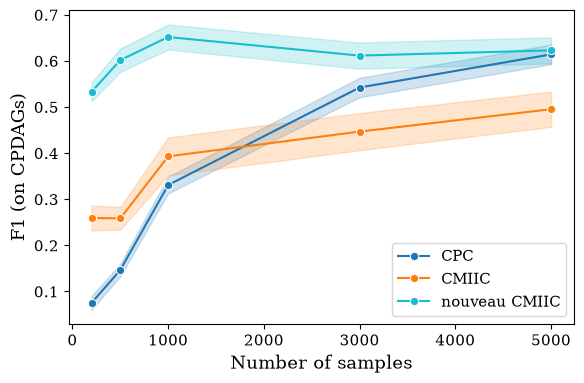

In [83]:
plot(df, 20, "F1-Score", "F1 (on CPDAGs)")

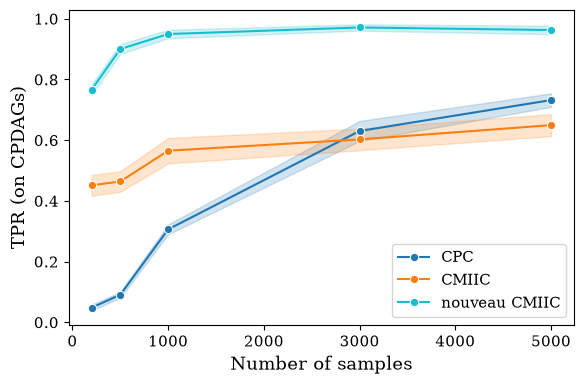

In [84]:
plot(df, 20, "TPR", "TPR (on CPDAGs)")

### Sur les squelettes

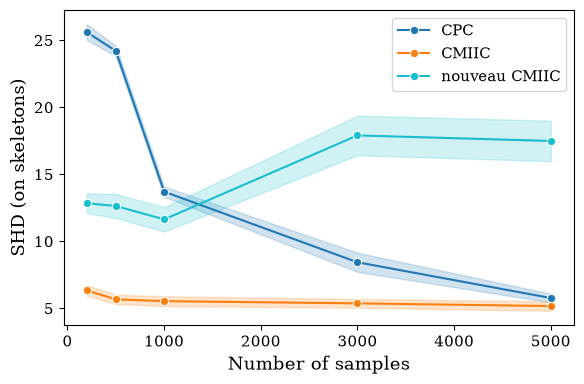

In [85]:
plot(df, 20, "SHD_skeleton", "SHD (on skeletons)")

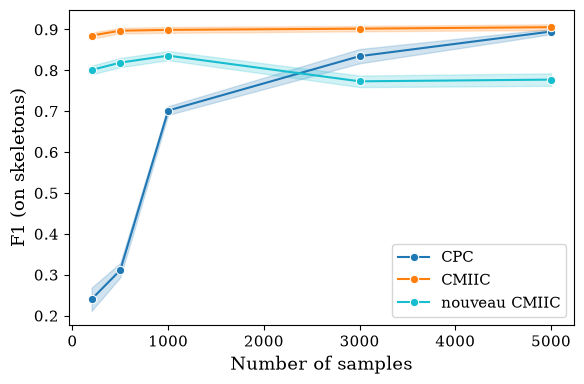

In [86]:
plot(df, 20, "F1-Score_skeleton", "F1 (on skeletons)")

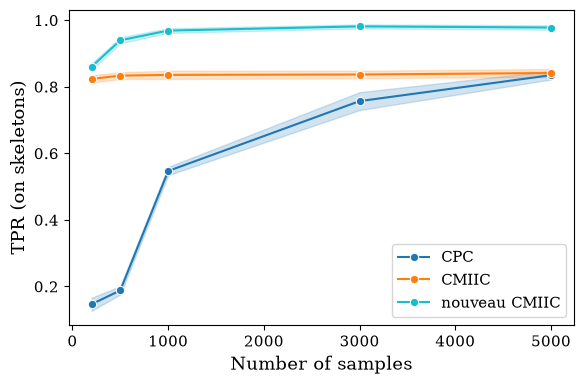

In [87]:
plot(df, 20, "TPR_skeleton", "TPR (on skeletons)")

# CBN Exponential/Clayton

In [88]:
df = load_pair("cbn_exp_clayton")

## 10 variables

### Temps d'exécution

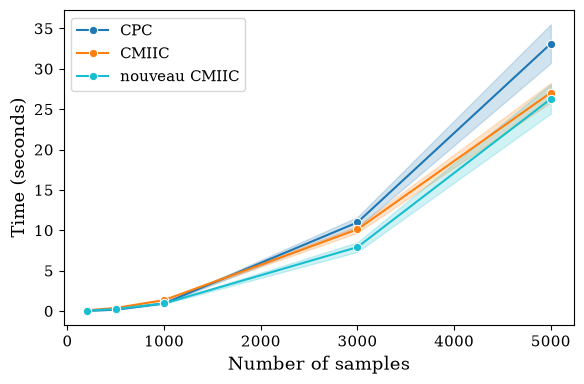

In [89]:
plot(df, 10, "time_s", "Time (seconds)")

### Sur les CPDAG

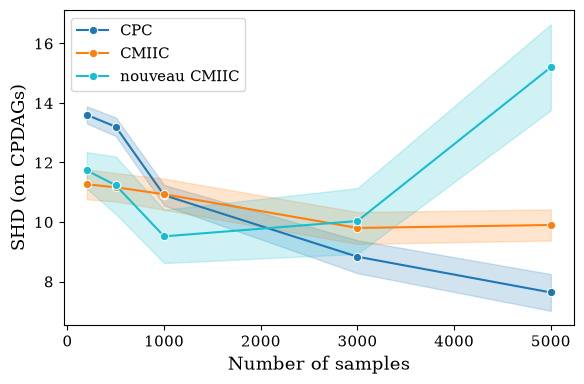

In [90]:
plot(df, 10, "SHD", "SHD (on CPDAGs)")

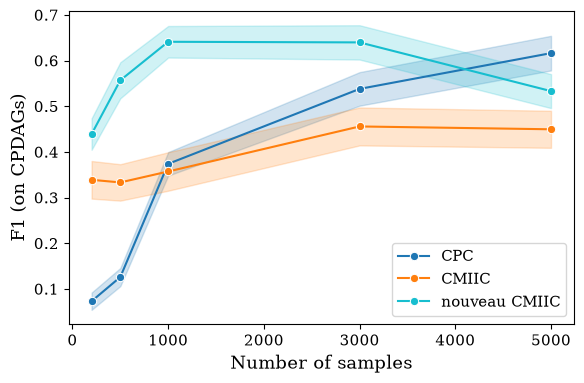

In [91]:
plot(df, 10, "F1-Score", "F1 (on CPDAGs)")

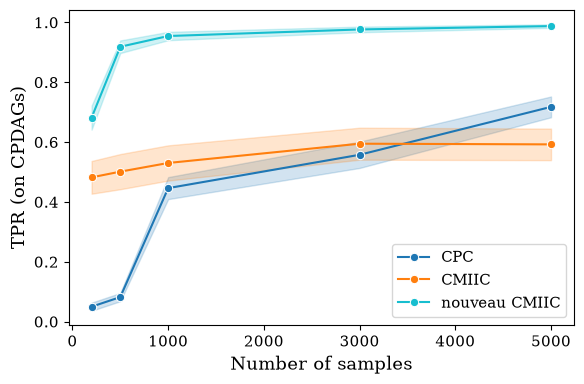

In [92]:
plot(df, 10, "TPR", "TPR (on CPDAGs)")

### Sur les squelettes

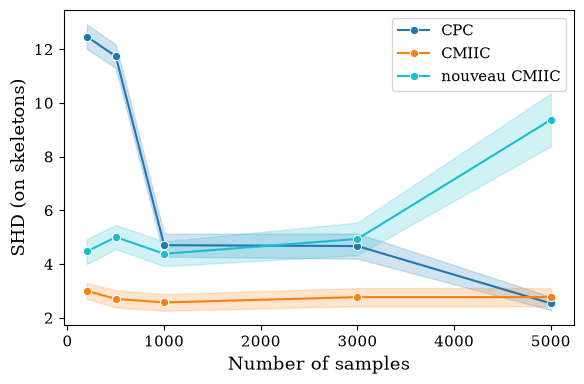

In [93]:
plot(df, 10, "SHD_skeleton", "SHD (on skeletons)")

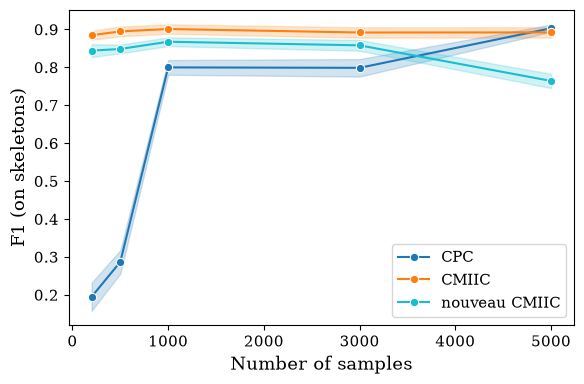

In [94]:
plot(df, 10, "F1-Score_skeleton", "F1 (on skeletons)")

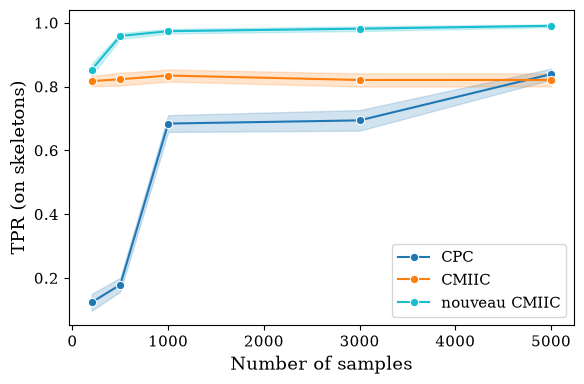

In [95]:
plot(df, 10, "TPR_skeleton", "TPR (on skeletons)")

## 20 variables

### Temps d'exécution

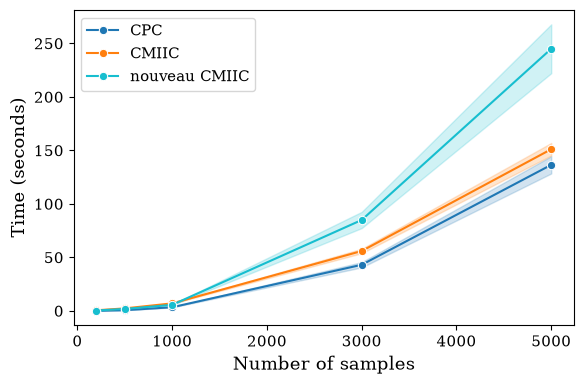

In [96]:
plot(df, 20, "time_s", "Time (seconds)")

### Sur les CPDAG

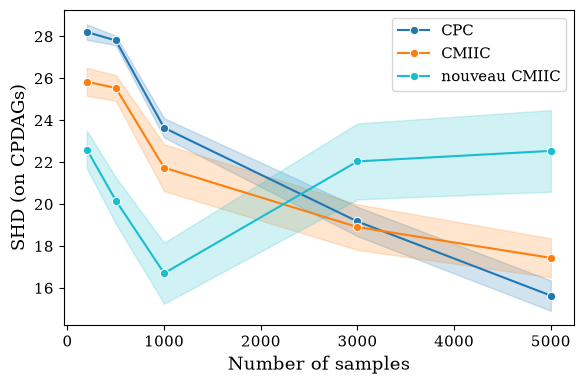

In [97]:
plot(df, 20, "SHD", "SHD (on CPDAGs)")

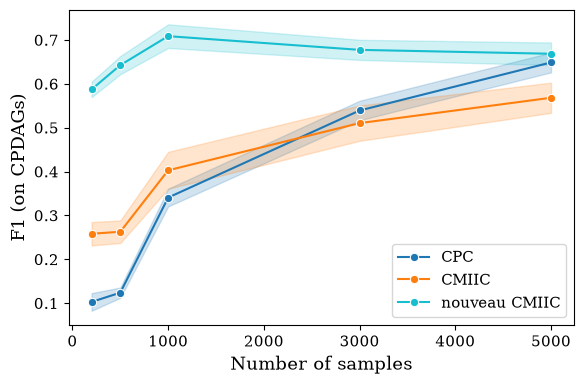

In [98]:
plot(df, 20, "F1-Score", "F1 (on CPDAGs)")

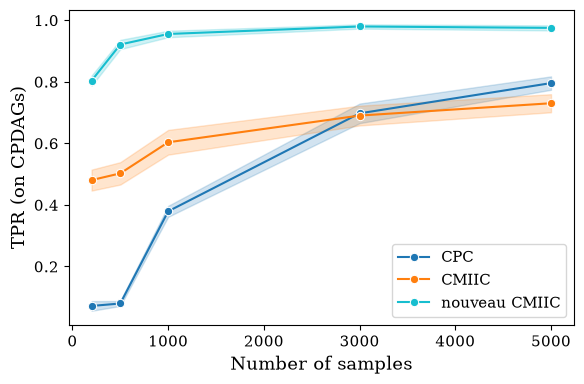

In [99]:
plot(df, 20, "TPR", "TPR (on CPDAGs)")

### Sur les squelettes

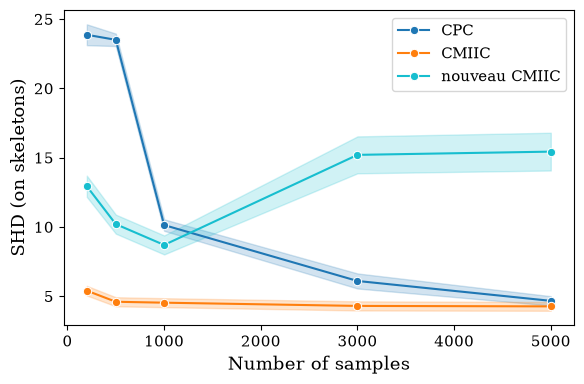

In [100]:
plot(df, 20, "SHD_skeleton", "SHD (on skeletons)")

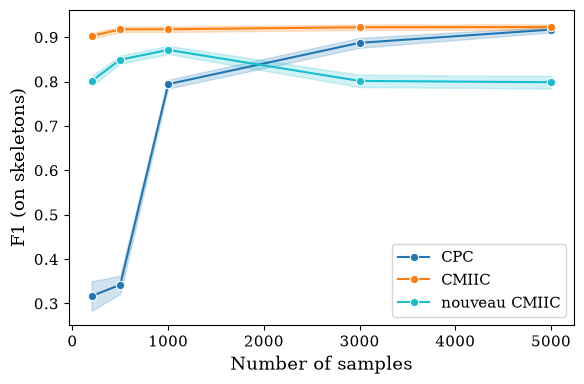

In [101]:
plot(df, 20, "F1-Score_skeleton", "F1 (on skeletons)")

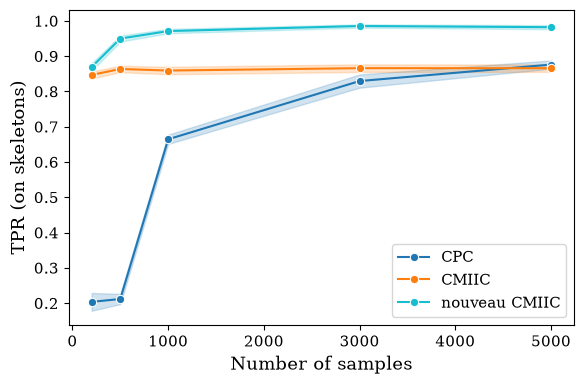

In [102]:
plot(df, 20, "TPR_skeleton", "TPR (on skeletons)")

# CBN Uniform/Mixture

In [103]:
df = load_pair("cbn_unif_mixture")

## 10 variables

### Temps d'exécution

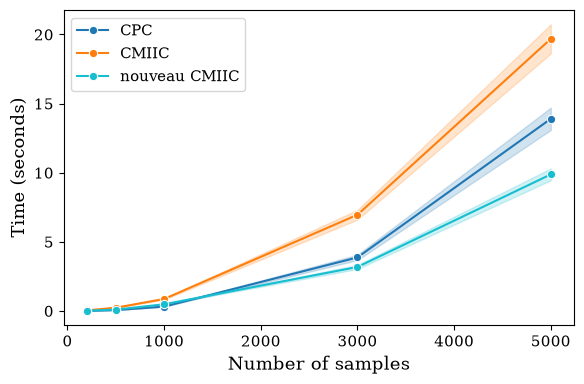

In [104]:
plot(df, 10, "time_s", "Time (seconds)")

### Sur les CPDAG

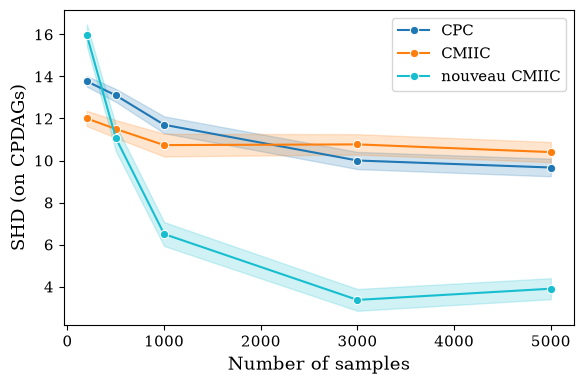

In [105]:
plot(df, 10, "SHD", "SHD (on CPDAGs)")

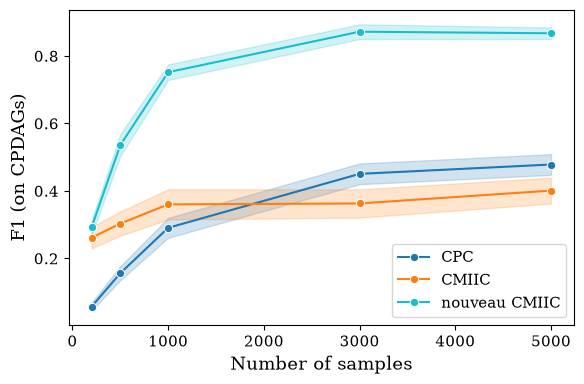

In [106]:
plot(df, 10, "F1-Score", "F1 (on CPDAGs)")

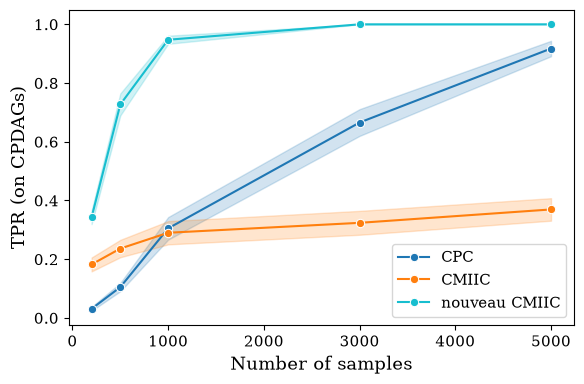

In [107]:
plot(df, 10, "TPR", "TPR (on CPDAGs)")

### Sur les squelettes

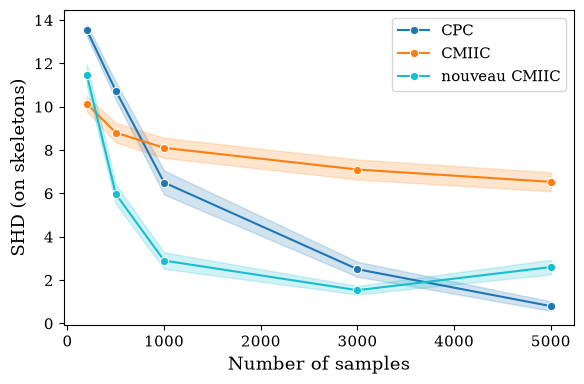

In [108]:
plot(df, 10, "SHD_skeleton", "SHD (on skeletons)")

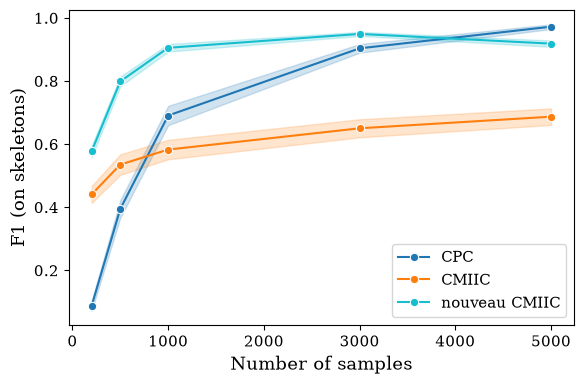

In [109]:
plot(df, 10, "F1-Score_skeleton", "F1 (on skeletons)")

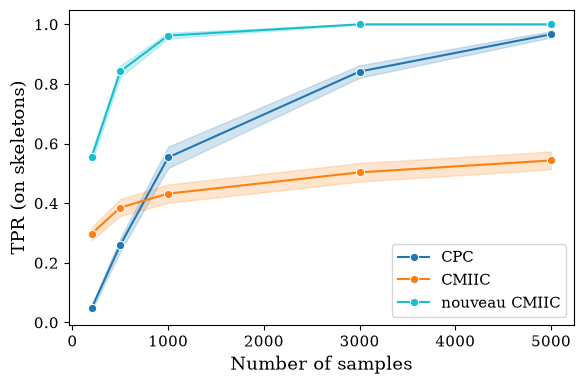

In [110]:
plot(df, 10, "TPR_skeleton", "TPR (on skeletons)")

## 20 variables

### Temps d'exécution

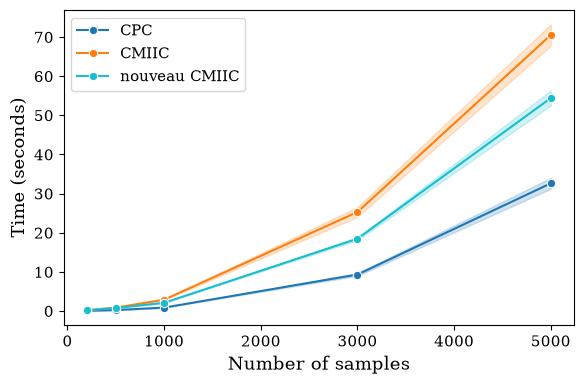

In [111]:
plot(df, 20, "time_s", "Time (seconds)")

### Sur les CPDAG

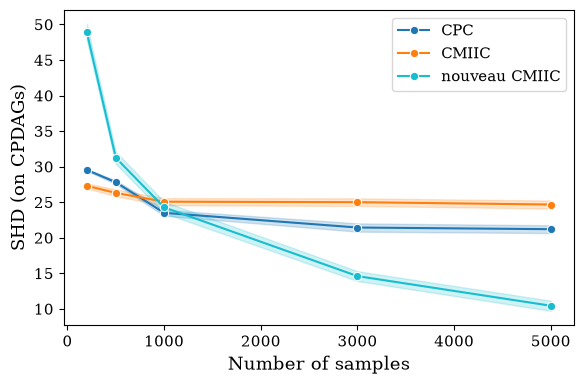

In [112]:
plot(df, 20, "SHD", "SHD (on CPDAGs)")

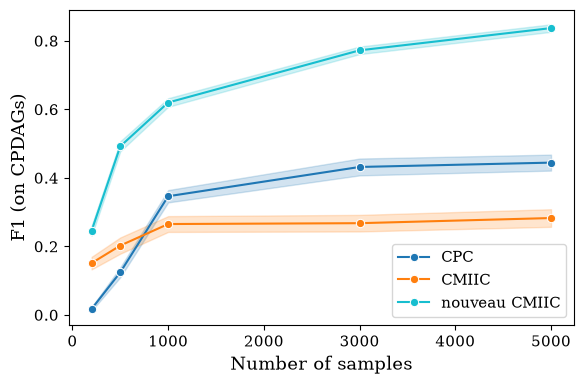

In [113]:
plot(df, 20, "F1-Score", "F1 (on CPDAGs)")

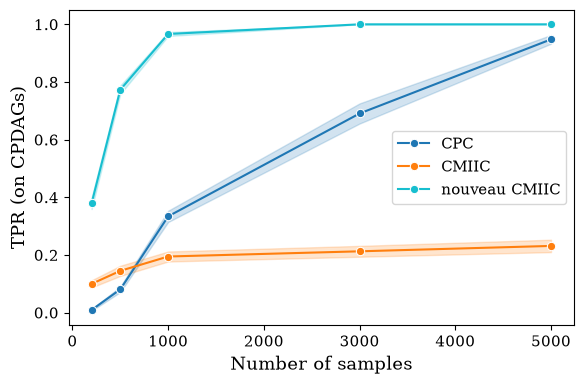

In [114]:
plot(df, 20, "TPR", "TPR (on CPDAGs)")

### Sur les squelettes

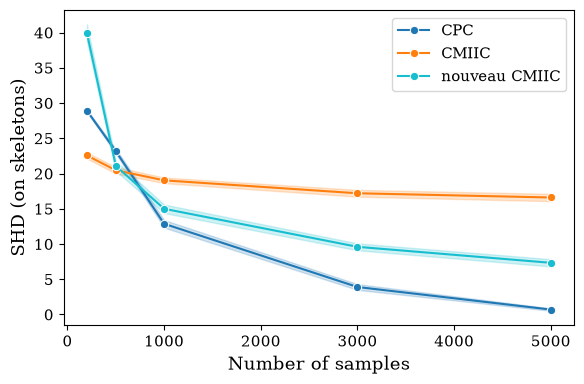

In [115]:
plot(df, 20, "SHD_skeleton", "SHD (on skeletons)")

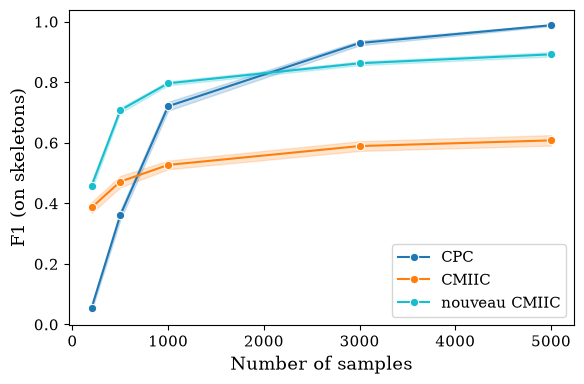

In [116]:
plot(df, 20, "F1-Score_skeleton", "F1 (on skeletons)")

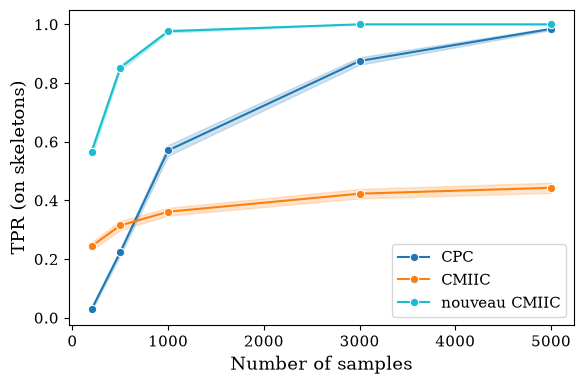

In [118]:
plot(df, 20, "TPR_skeleton", "TPR (on skeletons)")